# Importação das bibliotecas e base

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

In [3]:
df = pd.read_csv('/content/drive/MyDrive/TCC/TCC/base_processada.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21504 entries, 0 to 21503
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   codigo_municipio             21504 non-null  int64  
 1   municipio                    21504 non-null  object 
 2   Mes_Ano                      21504 non-null  object 
 3   AIH_Aprovadas                21504 non-null  int64  
 4   Valor_Total                  21504 non-null  float64
 5   Internacoes                  21504 non-null  int64  
 6   Dias_Permanencia             21504 non-null  int64  
 7   Media_Permanencia            21502 non-null  float64
 8   Obitos                       21504 non-null  int64  
 9   ano                          21504 non-null  int64  
 10  mes                          21504 non-null  int64  
 11  codigo_ibge                  21504 non-null  int64  
 12  populacao                    21504 non-null  float64
 13  pessoas_cadunico

# Análise do alvo



In [5]:
df['Valor_Total_real'].isna().sum()

np.int64(0)

In [6]:
(df['Valor_Total_real'] == 0).sum()

np.int64(2)

In [7]:
zeros = df[df['Valor_Total_real'] == 0]

print('Total de zeros:', len(zeros))

Total de zeros: 2


In [8]:
zeros[
    ['municipio', 'ano', 'mes',
     'Valor_Total_real', 'Internacoes', 'AIH_Aprovadas']
].head()

,municipio,ano,mes,Valor_Total_real,Internacoes,AIH_Aprovadas
6472,SAO LUIS DO PIAUI,2020,5,0.0,0,0
19053,AROEIRAS DO ITAIM,2025,2,0.0,0,0


In [9]:
pd.options.display.float_format = "{:,.2f}".format
df['Valor_Total_real'].describe()

,Valor_Total_real
count,"21,504.00"
mean,"111,658.35"
std,"562,391.10"
min,0.00
25%,"19,371.39"
50%,"35,890.50"
75%,"76,288.75"
max,"15,834,321.13"


mediana: R$ 35.890,50

média: R$ 111.658,35

Q3: R$ 76.288,75

máximo: R$ 15.834.321,13

média bastante superior a mediana

In [10]:
df.nlargest(
    15, 'Valor_Total_real'
)[
    ['municipio', 'ano', 'mes',
     'Valor_Total_real', 'Internacoes', 'AIH_Aprovadas']
]

#Maiores valores Teresina anos de pandemia 2020 e 2021

,municipio,ano,mes,Valor_Total_real,Internacoes,AIH_Aprovadas
8727,TERESINA,2021,3,"15,834,321.13",4577,4666
6935,TERESINA,2020,7,"15,066,026.43",4185,4214
8951,TERESINA,2021,4,"14,456,863.91",4464,4572
9175,TERESINA,2021,5,"13,566,759.68",4749,4764
7159,TERESINA,2020,8,"11,177,018.02",3976,3998
9399,TERESINA,2021,6,"10,516,649.23",4503,4534
7607,TERESINA,2020,10,"10,409,439.72",4184,4222
7383,TERESINA,2020,9,"10,147,177.31",4105,4133
6711,TERESINA,2020,6,"10,123,546.58",3992,4017
9623,TERESINA,2021,7,"9,963,939.66",4416,4504


In [11]:
df['Valor_Total_real'].skew()

np.float64(14.90144146135404)

skew >1	assimetria positiva forte

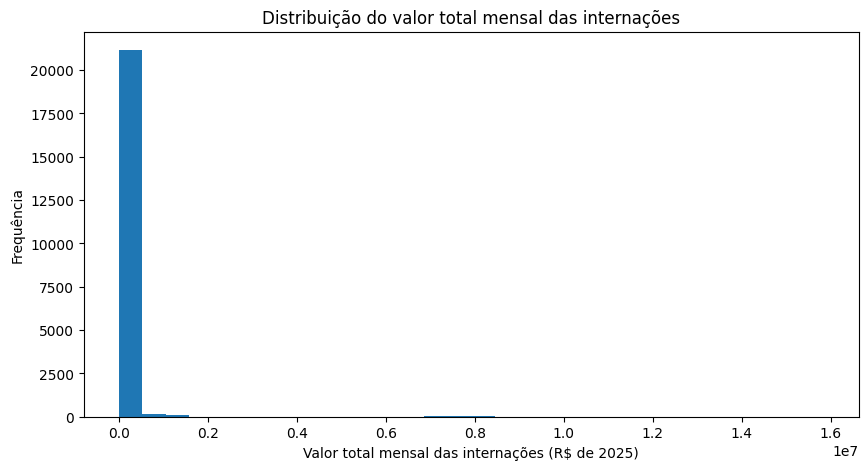

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(df['Valor_Total_real'], bins=30)

plt.xlabel('Valor total mensal das internações (R$ de 2025)')
plt.ylabel('Frequência')
plt.title('Distribuição do valor total mensal das internações')

plt.show()

#O valor mensal está concentrado nos valores menores, enquanto algumas observações possuem custos extremamente altos e formam uma cauda longa a direita

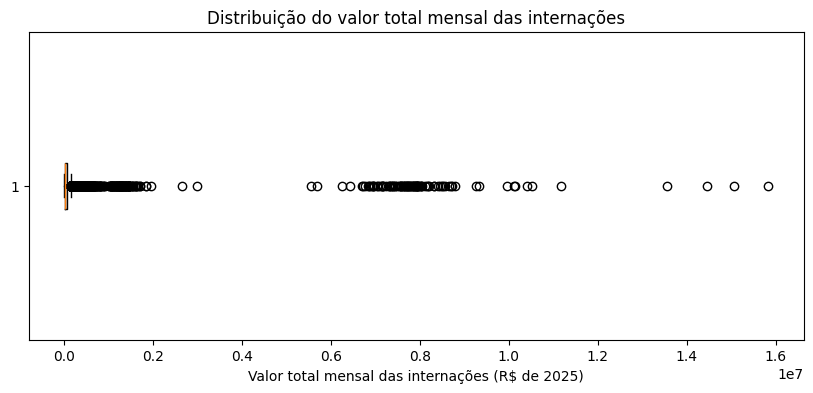

In [13]:
plt.figure(figsize=(10, 4))

plt.boxplot(df['Valor_Total_real'], vert=False)

plt.xlabel('Valor total mensal das internações (R$ de 2025)')
plt.title('Distribuição do valor total mensal das internações')

plt.show()

#A caixinha e a mediana estão espremidas perto do zero porque existem valores muito altos

In [14]:
#Transformação logarítmica
df['log_valor_total_real'] = np.log1p(df['Valor_Total_real'])

In [15]:
df['log_valor_total_real'].describe()

,log_valor_total_real
count,"21,504.00"
mean,10.60
std,1.15
min,0.00
25%,9.87
50%,10.49
75%,11.24
max,16.58


In [16]:
df['log_valor_total_real'].skew()

np.float64(0.538852648838053)

Caiu de 14,90 para 0,54 com log1p(), ficando muito mais próxima de uma distribuição simétrica

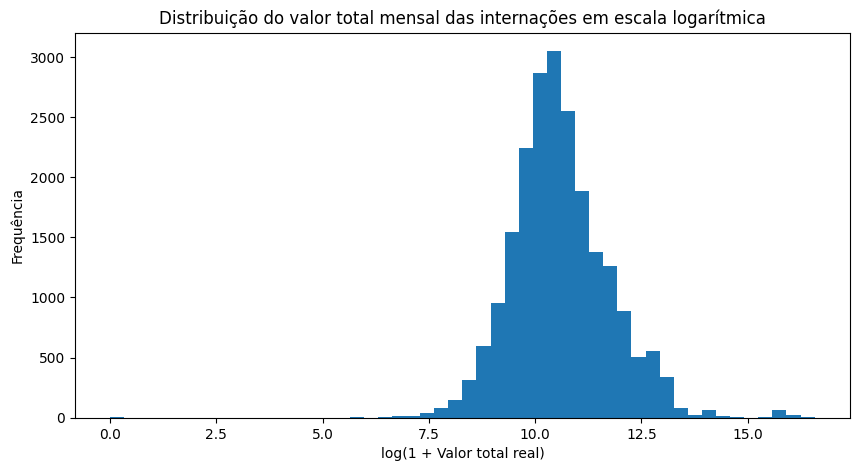

In [17]:
plt.figure(figsize=(10, 5))

plt.hist(df['log_valor_total_real'], bins=50)

plt.xlabel('log(1 + Valor total real)')
plt.ylabel('Frequência')
plt.title('Distribuição do valor total mensal das internações em escala logarítmica')

plt.show()

In [18]:
df['valor_medio_internacao_real'].describe()

,valor_medio_internacao_real
count,"21,502.00"
mean,"1,445.04"
std,911.70
min,181.98
25%,905.98
50%,"1,208.90"
75%,"1,682.24"
max,"17,055.41"


Q1 (25%)     = 905,98

Mediana      = 1.208,90

Q3 (75%)     = 1.682,24

Máximo       = 17.055,41

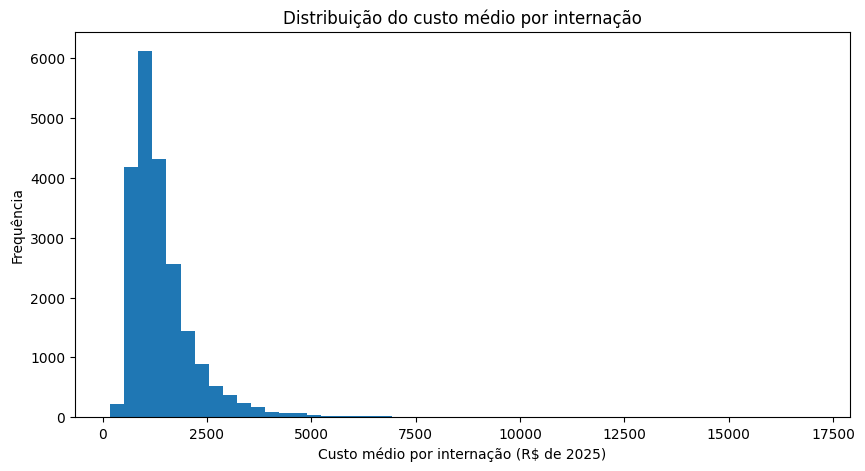

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(df['valor_medio_internacao_real'], bins=50)

plt.xlabel('Custo médio por internação (R$ de 2025)')#quanto custou, em média, cada internação naquele município-mês
plt.ylabel('Frequência')
plt.title('Distribuição do custo médio por internação')

plt.show()

#maior parte das observações está concentrada em valores relativamente baixos e existe uma cauda longa para a direita
#custo médio continua assimétrico a direita, mas menos disperso que o Valor Total

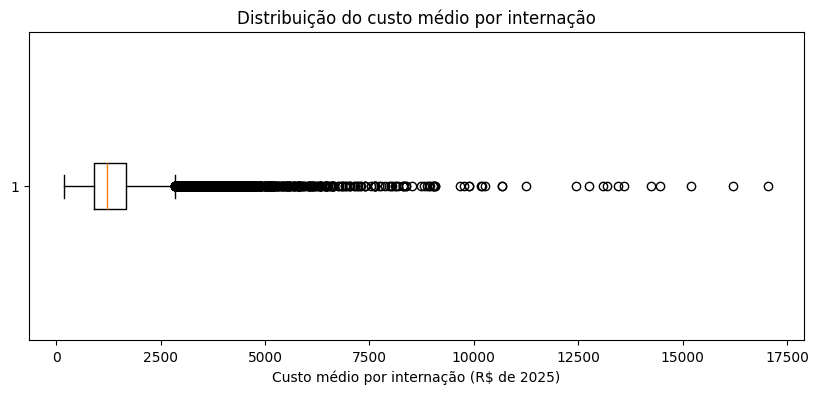

In [20]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df['valor_medio_internacao_real'].dropna(),
    vert=False
)

plt.xlabel('Custo médio por internação (R$ de 2025)')
plt.title('Distribuição do custo médio por internação')

plt.show()

In [21]:
df.loc[
    df['valor_medio_internacao_real'].nlargest(20).index,
    ['municipio', 'ano', 'mes', 'Internacoes',
     'Valor_Total_real', 'valor_medio_internacao_real']
]

,municipio,ano,mes,Internacoes,Valor_Total_real,valor_medio_internacao_real
14995,SOCORRO DO PIAUI,2023,7,9,"153,498.73","17,055.41"
9584,SANTA FILOMENA,2021,7,10,"162,156.76","16,215.68"
18901,FRANCISCO MACEDO,2025,1,7,"106,359.07","15,194.15"
17225,SAO MIGUEL DA BAIXA GRANDE,2024,5,9,"130,133.59","14,459.29"
10327,BELA VISTA DO PIAUI,2021,11,10,"142,452.43","14,245.24"
19044,ALEGRETE DO PIAUI,2025,2,11,"149,680.50","13,607.32"
267,CAMPO ALEGRE DO FIDALGO,2018,2,11,"148,089.12","13,462.65"
11348,PAQUETA,2022,3,9,"118,690.83","13,187.87"
17287,CAJAZEIRAS DO PIAUI,2024,6,11,"143,977.24","13,088.84"
7071,MIGUEL LEAO,2020,8,3,"38,265.21","12,755.07"


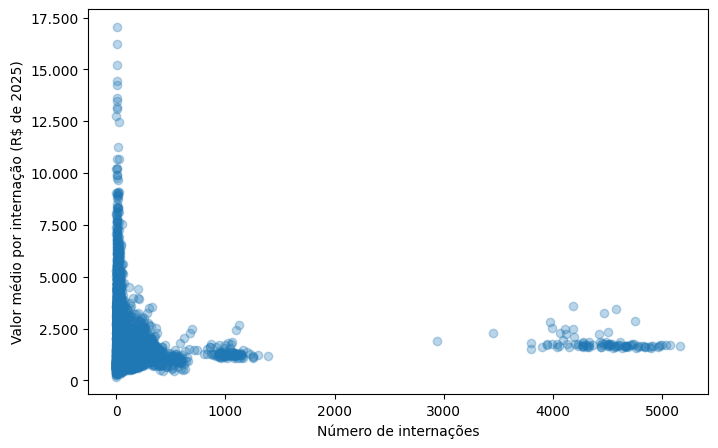

In [22]:
import matplotlib.ticker as ticker

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Internacoes'],
    df['valor_medio_internacao_real'],
    alpha=0.3
)

plt.xlabel('Número de internações')
plt.ylabel('Valor médio por internação (R$ de 2025)')

# Função para formatar o número com separador de milhar (ponto)
def formata_milhar(x, pos):
    return f'{x:,.0f}'.replace(',', '.')

# Aplica o formatador no eixo Y
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(formata_milhar))

plt.savefig('dispersao_valor.pdf', dpi=300, bbox_inches='tight')

plt.show()

#Os custos médios extremamente elevados estão concentrados em observações com poucas internações?

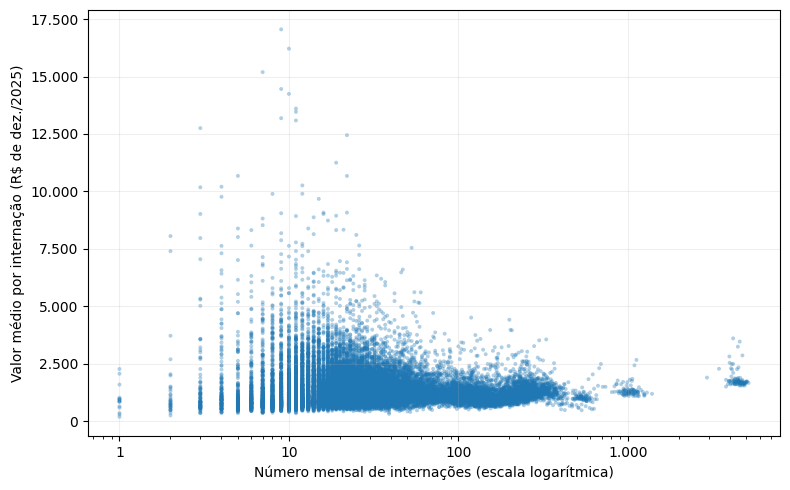

In [23]:
# Selecionar observações válidas para o gráfico
dados = df.loc[
    (df['Internacoes'] > 0) &
    np.isfinite(df['valor_medio_internacao_real']),
    ['Internacoes', 'valor_medio_internacao_real']
].copy()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    dados['Internacoes'],
    dados['valor_medio_internacao_real'],
    alpha=0.35,
    s=8,
    edgecolors='none'
)

# Escala logarítmica no eixo X
ax.set_xscale('log')

ax.set_xlabel('Número mensal de internações (escala logarítmica)')
ax.set_ylabel('Valor médio por internação (R$ de dez./2025)')

# Formatação dos números
def formata_milhar(x, pos):
    return f'{x:,.0f}'.replace(',', '.')

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(formata_milhar)
)
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(formata_milhar)
)

ax.grid(alpha=0.20)
fig.tight_layout()

fig.savefig('dispersao log.png', dpi=300, bbox_inches='tight')
plt.show()


Enquanto os maiores valores totais de internação concentram-se em Teresina com maior volume de atendimentos, o custo médio por internação apresenta valores elevados também em municípios de pequeno porte, frequentemente em observações com baixo número de internações.

A média é menos estável quando há poucas internações. Municípios pequenos e com poucas internações podem apresentar custos médios muito elevados.

# Análise temporal

Comportamento geral do gasto ao longo do tempo

In [24]:
temporal = (
    df.groupby(['ano', 'mes'], as_index=False)#agrupando todas as observações que pertencem ao mesmo ano e ao mesmo mês
      .agg(
          valor_total=('Valor_Total_real', 'sum'), #agregando os dados de cada grupo
          internacoes=('Internacoes', 'sum'),
          aih=('AIH_Aprovadas', 'sum')
      )
)

temporal['valor_medio_internacao_real'] = (
    temporal['valor_total'] / temporal['internacoes']
)

temporal['data'] = pd.to_datetime(
    dict(
        year=temporal['ano'],
        month=temporal['mes'],
        day=1
    )
)

temporal.head()

,ano,mes,valor_total,internacoes,aih,valor_medio_internacao_real,data
0,2018,1,"22,675,829.12",17125,17184,"1,324.14",2018-01-01
1,2018,2,"20,126,255.60",14975,15066,"1,343.99",2018-02-01
2,2018,3,"23,411,005.35",17459,17552,"1,340.91",2018-03-01
3,2018,4,"23,446,855.11",18075,18224,"1,297.20",2018-04-01
4,2018,5,"24,732,058.70",18738,18885,"1,319.89",2018-05-01


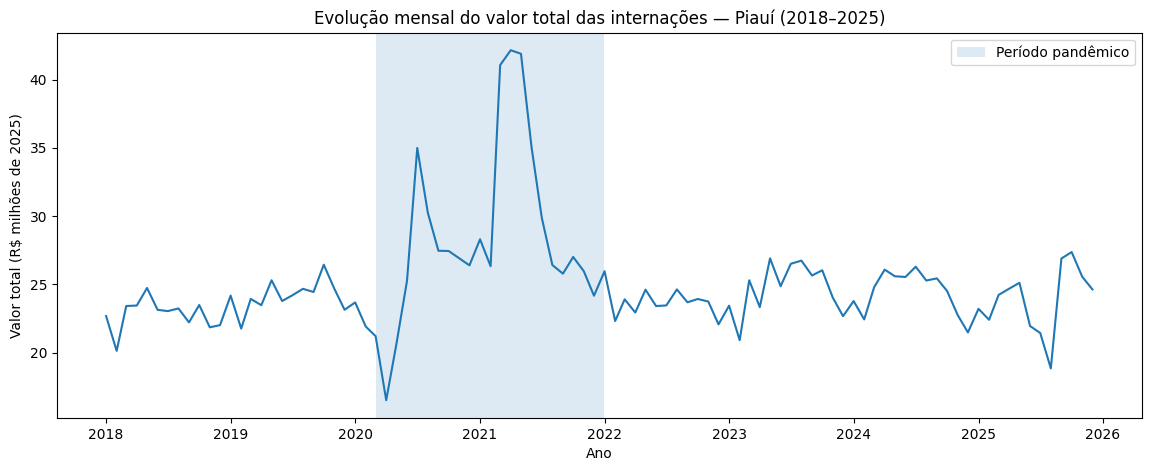

In [25]:
plt.figure(figsize=(14, 5))

plt.plot(
    temporal['data'],
    temporal['valor_total'] / 1_000_000
)

plt.xlabel('Ano')
plt.ylabel('Valor total (R$ milhões de 2025)')
plt.title('Evolução mensal do valor total das internações — Piauí (2018–2025)')

plt.axvspan(
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2021-12-31'),
    alpha=0.15,
    label='Período pandêmico'
)

plt.legend()
plt.show()

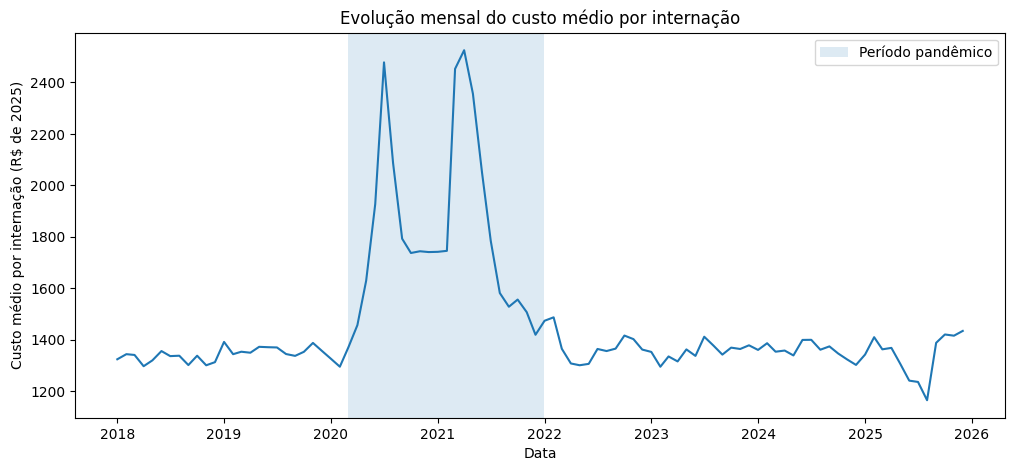

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(
    temporal['data'],
    temporal['valor_medio_internacao_real']
)

plt.xlabel('Data')
plt.ylabel('Custo médio por internação (R$ de 2025)')
plt.title('Evolução mensal do custo médio por internação')

plt.axvspan(
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2021-12-31'),
    alpha=0.15,
    label='Período pandêmico'
)

plt.legend()
plt.show()

Antes de 2020: o custo médio fica relativamente estável, em torno de R$ 1,3–1,4 mil, enquanto o valor total também varia dentro de uma faixa relativamente estável.

2020–2021: aparecem os grandes picos nas duas séries. O custo médio ultrapassa 2,4 mil e o valor total passa de R$ 40 milhões em alguns meses.

A partir de 2022: o custo médio retorna para algo próximo de 1,3–1,5 mil e o valor total volta para uma faixa próxima de R$ 22–27 milhões.

Como o custo médio resulta da razão entre o valor total e o número de internações, a semelhança entre as trajetórias não implica que sua elevação decorra exclusivamente do aumento dos gastos totais. Alterações no volume de internações também podem contribuir para esse comportamento.

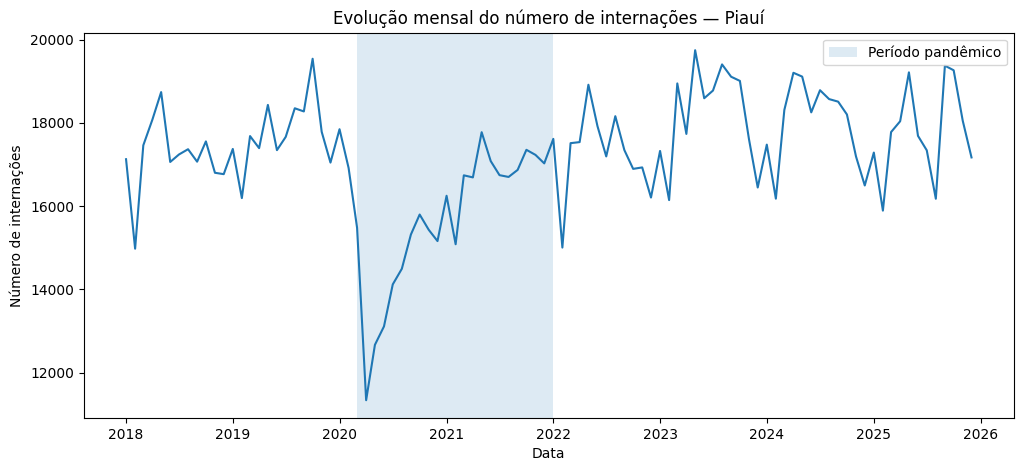

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    temporal['data'],
    temporal['internacoes']
)

plt.xlabel('Data')
plt.ylabel('Número de internações')
plt.title('Evolução mensal do número de internações — Piauí')

plt.axvspan(
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2021-12-31'),
    alpha=0.15,
    label='Período pandêmico'
)

plt.legend()
plt.show()

2020: queda de internações - pressão para cima no custo médio

2021: recuperação das internações + valor total elevado - custo médio ainda elevado

In [28]:
base_2019 = temporal.loc[
    temporal['ano'] == 2019,
    ['valor_total', 'internacoes', 'valor_medio_internacao_real']
].mean()  #Como valor total, internações e custo médio evoluíram em relação ao nível médio pré-pandemia de 2019?

In [29]:
temporal['valor_total_indice'] = (
    temporal['valor_total'] / base_2019['valor_total'] * 100
)

temporal['internacoes_indice'] = (
    temporal['internacoes'] / base_2019['internacoes'] * 100
)

temporal['custo_medio_indice'] = (
    temporal['valor_medio_internacao_real']
    / base_2019['valor_medio_internacao_real']
    * 100
)

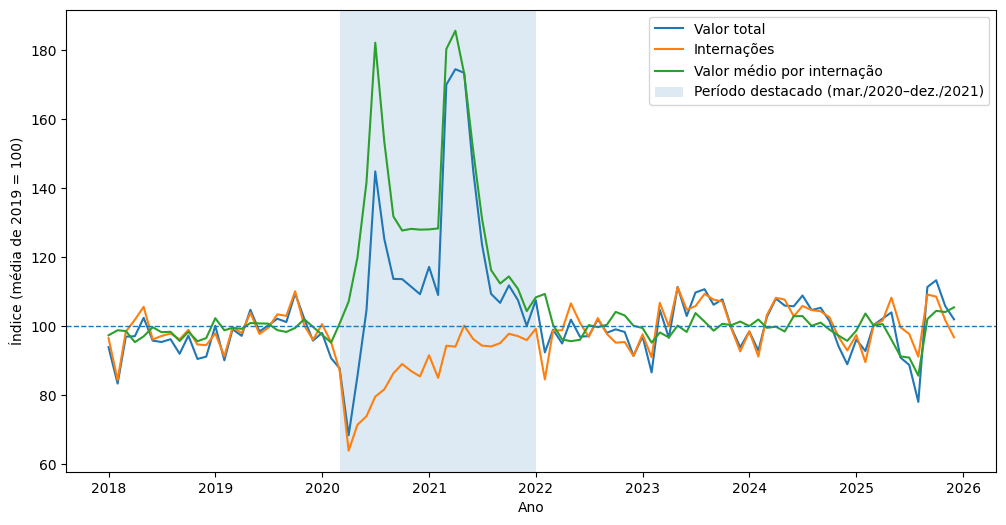

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(
    temporal['data'],
    temporal['valor_total_indice'],
    label='Valor total'
)


plt.plot(
    temporal['data'],
    temporal['internacoes_indice'],
    label='Internações'
)

plt.plot(
    temporal['data'],
    temporal['custo_medio_indice'],
    label='Valor médio por internação'
)

plt.axhline(100, linestyle='--', linewidth=1) #linha pontilhada em 100 representa a média mensal de 2019

plt.xlabel('Ano')
plt.ylabel('Índice (média de 2019 = 100)')

plt.axvspan(
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2021-12-31'),
    alpha=0.15,
    label='Período destacado (mar./2020–dez./2021)'
)

plt.legend()

plt.savefig('analise_temporal.png', dpi=300, bbox_inches='tight')

plt.show()

A análise em índice de base fixa (média de 2019 = 100) evidencia uma alteração expressiva na dinâmica hospitalar durante o período pandêmico. No início de 2020, as internações despencam, chegando perto de 65–70 no índice, algo como 30–35% abaixo do nível médio de 2019. O valor total também cai inicialmente. Ainda em 2020, o valor total sobe fortemente, enquanto as internações continuam abaixo de 100, o que resulta no custo médio disparar para mais de 180.

A partir de 2022, os três indicadores retornam a patamares mais próximos da referência pré-pandemia.

# Análise por municípios

In [31]:
municipios = (
    df.groupby(['codigo_ibge', 'municipio'], as_index=False) #agrupa todas as linhas pertencentes ao mesmo município
      .agg( #agrega todas as observações de cada município
          valor_total_real=('Valor_Total_real', 'sum'), #valor total de todos os meses e anos daquele município
          internacoes=('Internacoes', 'sum'), #total acumulado de internações
          aih_aprovadas=('AIH_Aprovadas', 'sum'), #total acumulado de aih aprovadas
          populacao_media=('populacao', 'mean') #média da população ao longo das observações do município
      )
)

municipios['perc_valor_total'] = (
    municipios['valor_total_real']
    / municipios['valor_total_real'].sum()
    * 100
) #participação percentual de cada município no valor total de toda a base

municipios = municipios.sort_values(
    'valor_total_real',
    ascending=False
) #ordena os municípios pelo valor total, maior para o menor

municipios.head(15)

#onde se concentra o gasto/produção hospitalar acumulada

,codigo_ibge,municipio,valor_total_real,internacoes,aih_aprovadas,populacao_media,perc_valor_total
215,2211001,TERESINA,"778,434,103.99",426847,431355,"875,803.00",32.42
150,2207702,PARNAIBA,"130,741,855.42",96295,96594,"159,679.62",5.45
205,2210607,SAO RAIMUNDO NONATO,"47,564,397.15",44426,44505,"37,368.50",1.98
82,2203909,FLORIANO,"44,997,585.78",31861,31917,"61,565.75",1.87
163,2208403,PIRIPIRI,"44,125,942.76",28101,28186,"65,211.38",1.84
159,2208007,PICOS,"41,816,886.65",29249,29522,"81,548.88",1.74
46,2202208,CAMPO MAIOR,"39,024,771.60",29685,29746,"46,653.12",1.63
141,2207009,OEIRAS,"39,023,556.76",26535,26643,"37,972.12",1.63
6,2200400,ALTOS,"36,288,590.84",24168,24409,"44,610.88",1.51
107,2205508,JOSE DE FREITAS,"34,719,871.00",23093,23262,"41,408.88",1.45


In [32]:
municipios['perc_acumulado'] = ( #soma progressiva desses percentuais
    municipios['perc_valor_total'].cumsum()
)

municipios[
    ['municipio', 'valor_total_real',
     'perc_valor_total', 'perc_acumulado']
].head(20)

,municipio,valor_total_real,perc_valor_total,perc_acumulado
215,TERESINA,"778,434,103.99",32.42,32.42
150,PARNAIBA,"130,741,855.42",5.45,37.86
205,SAO RAIMUNDO NONATO,"47,564,397.15",1.98,39.85
82,FLORIANO,"44,997,585.78",1.87,41.72
163,PIRIPIRI,"44,125,942.76",1.84,43.56
159,PICOS,"41,816,886.65",1.74,45.30
46,CAMPO MAIOR,"39,024,771.60",1.63,46.92
141,OEIRAS,"39,023,556.76",1.63,48.55
6,ALTOS,"36,288,590.84",1.51,50.06
107,JOSE DE FREITAS,"34,719,871.00",1.45,51.51


In [33]:
print(
    'Teresina:',
    municipios.iloc[0]['perc_valor_total']
)

print(
    'Top 5:',
    municipios.head(5)['perc_valor_total'].sum()
)

print(
    'Top 10:',
    municipios.head(10)['perc_valor_total'].sum()
)

Teresina: 32.41987846546553
Top 5: 43.55767543125349
Top 10: 51.50709770576499


Entre os 224 municípios, apenas os 10 primeiros concentram mais da metade de todo o valor total das internações no período analisado

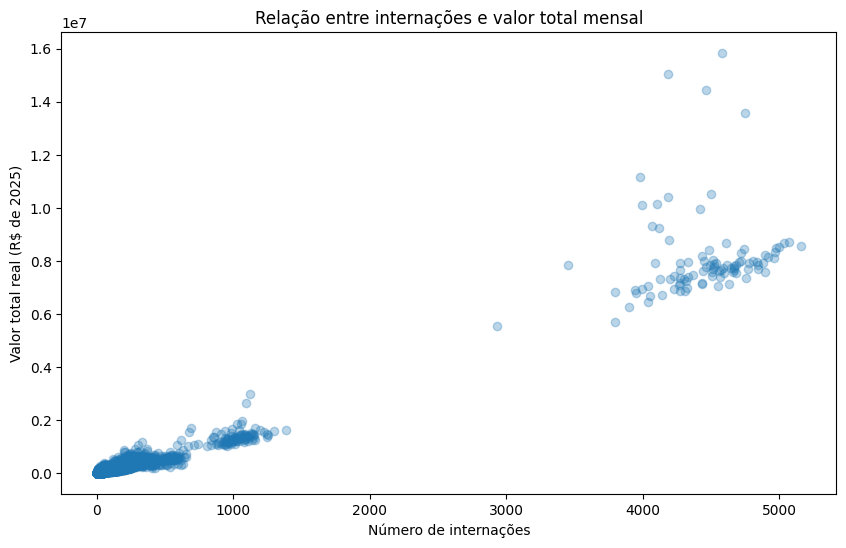

In [34]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Internacoes'],
    df['Valor_Total_real'],
    alpha=0.3
)

plt.xlabel('Número de internações')
plt.ylabel('Valor total real (R$ de 2025)')
plt.title('Relação entre internações e valor total mensal')

plt.show()

In [35]:
#Considerando todas as internações registradas daquele município no período inteiro, qual foi o custo médio por internação?
municipios = (
    df.groupby(['codigo_ibge', 'municipio'], as_index=False)
      .agg(
          valor_total_real=('Valor_Total_real', 'sum'),
          internacoes=('Internacoes', 'sum'),
          aih_aprovadas=('AIH_Aprovadas', 'sum'),
          populacao_media=('populacao', 'mean')
      )
)

municipios['valor_medio_internacao_real'] = (
    municipios['valor_total_real']
    / municipios['internacoes']
)

municipios_custo = municipios.sort_values(
    'valor_medio_internacao_real',
    ascending=False
)

municipios_custo.head(15)

#quanto custa, em média, cada internação em cada município

,codigo_ibge,municipio,valor_total_real,internacoes,aih_aprovadas,populacao_media,valor_medio_internacao_real
201,2210383,SAO MIGUEL DA BAIXA GRANDE,"1,643,566.94",717,721,"2,369.00","2,292.28"
176,2209203,SANTA FILOMENA,"2,475,256.50",1116,1116,"6,201.00","2,217.97"
147,2207504,PALMEIRAIS,"10,331,024.51",4814,4840,"13,964.12","2,146.04"
129,2206407,MONSENHOR GIL,"8,898,285.16",4267,4310,"10,466.75","2,085.37"
92,2204600,HUGO NAPOLEAO,"3,246,326.52",1631,1661,"3,707.38","1,990.39"
195,2210052,SAO JOSE DO DIVINO,"3,296,210.70",1667,1669,"5,163.00","1,977.33"
9,2200608,ANGICAL DO PIAUI,"5,179,661.70",2621,2623,"6,846.12","1,976.22"
21,2201408,BARRO DURO,"4,538,431.42",2316,2376,"6,859.25","1,959.60"
188,2209807,SAO GONCALO DO PIAUI,"3,434,712.36",1764,1784,"4,961.38","1,947.12"
222,2211605,VILA NOVA DO PIAUI,"1,483,004.08",779,780,"2,958.62","1,903.73"


Quando deixa de medir volume acumulado começa a aparecer os municípios pequenos

# Análise de correlações

Como as variáveis se relacionam entre si

In [36]:
base_corr = df[
    ['Internacoes', 'Valor_Total_real']
].dropna()

pearson = pearsonr( #correlação de Pearson entre número de internações e valor total
    base_corr['Internacoes'],
    base_corr['Valor_Total_real']
)

spearman = spearmanr( #relação monotônica, quando uma variável aumenta, a outra tende a aumentar também?
    base_corr['Internacoes'],
    base_corr['Valor_Total_real']
)

print('Pearson:', pearson)
print('Spearman:', spearman)

Pearson: PearsonRResult(statistic=np.float64(0.9721814844876908), pvalue=np.float64(0.0))
Spearman: SignificanceResult(statistic=np.float64(0.8582164082725353), pvalue=np.float64(0.0))


Person:

próximo de +1 → relação positiva forte

próximo de  0 → pouca relação linear

próximo de -1 → relação negativa forte

0.9729 → observações com maior número de internações tendem a apresentar maior valor total, com uma relação linear muito forte

In [37]:
vars_hospitalares = [
    'Valor_Total_real',
    'Internacoes',
    'AIH_Aprovadas',
    'Dias_Permanencia',
    'Media_Permanencia'
]

df[vars_hospitalares].corr().round(3) #calcula uma matriz de correlação Pearson

,Valor_Total_real,Internacoes,AIH_Aprovadas,Dias_Permanencia,Media_Permanencia
Valor_Total_real,1.00,0.97,0.97,0.97,0.04
Internacoes,0.97,1.00,1.00,0.99,0.02
AIH_Aprovadas,0.97,1.00,1.00,0.99,0.03
Dias_Permanencia,0.97,0.99,0.99,1.00,0.06
Media_Permanencia,0.04,0.02,0.03,0.06,1.00


Valor_Total_real, Internacoes, AIH_Aprovadas e Dias_Permanencia são fortemente relacionadas ao volume da atividade hospitalar. Quanto maior a produção hospitalar de um município-mês, maiores tendem a ser todas elas.

Media_Permanencia não mede volume, mede aproximadamente quantos dias, em média, cada internação dura. Por isso ela praticamente não acompanha o tamanho da produção.

In [38]:
vars_modelo = [
    'valor_medio_internacao_real',
    'Internacoes',
    'AIH_Aprovadas',
    'Dias_Permanencia',
    'Media_Permanencia',
    'populacao'
]

df[vars_modelo].corr().round(3)

,valor_medio_internacao_real,Internacoes,AIH_Aprovadas,Dias_Permanencia,Media_Permanencia,populacao
valor_medio_internacao_real,1.00,0.00,0.00,0.02,0.41,0.02
Internacoes,0.00,1.00,1.00,0.99,0.02,0.99
AIH_Aprovadas,0.00,1.00,1.00,0.99,0.03,0.99
Dias_Permanencia,0.02,0.99,0.99,1.00,0.06,0.99
Media_Permanencia,0.41,0.02,0.03,0.06,1.00,0.03
populacao,0.02,0.99,0.99,0.99,0.03,1.00


Não existe associação linear relevante entre o número de Internacoes, AIH_Aprovadas, Dias_Permanencia e o custo_medio_internacao_real.

Observações com maior média de permanência tendem a apresentar maior custo médio por internação. Uma internação que dura mais tempo pode envolver maior utilização de recursos hospitalares.



```
Multicolinearidade extremamente forte:

Internações × AIH              = 1.000
Internações × Dias permanência = 0.995
Internações × População        = 0.989

AIH × Dias permanência         = 0.995
AIH × População                = 0.989

Dias permanência × População   = 0.990
```



In [39]:
vars_modelo = [
    'valor_medio_internacao_real',
    'Internacoes',
    'AIH_Aprovadas',
    'Dias_Permanencia',
    'Media_Permanencia',
    'populacao'
]

corr_spearman = (
    df[vars_modelo]
    .corr(method='spearman')
    .round(3)
)

corr_spearman

,valor_medio_internacao_real,Internacoes,AIH_Aprovadas,Dias_Permanencia,Media_Permanencia,populacao
valor_medio_internacao_real,1.00,0.01,0.01,0.17,0.48,0.04
Internacoes,0.01,1.00,1.00,0.92,-0.01,0.84
AIH_Aprovadas,0.01,1.00,1.00,0.92,-0.00,0.84
Dias_Permanencia,0.17,0.92,0.92,1.00,0.33,0.80
Media_Permanencia,0.48,-0.01,-0.00,0.33,1.00,0.03
populacao,0.04,0.84,0.84,0.80,0.03,1.00


Observações que ocupam posições mais altas em média de permanência também tendem a ocupar posições mais altas em custo médio por internação

In [40]:
def calcular_correlacoes(dados, alvo, variavel):
    pares = dados[[alvo, variavel]].dropna()

    r, p_pearson = pearsonr(pares[alvo], pares[variavel])
    rho, p_spearman = spearmanr(pares[alvo], pares[variavel])

    return {
        "n": len(pares),
        "Pearson_r": round(r, 3),
        "p_Pearson": p_pearson,
        "Spearman_rho": round(rho, 3),
        "p_Spearman": p_spearman
    }

alvo = "valor_medio_internacao_real"

# Correlações na base mensal
variaveis_mensais = [
    "Media_Permanencia",
    "internacoes_1000hab"
]

for variavel in variaveis_mensais:
    print(variavel)
    print(calcular_correlacoes(df, alvo, variavel))


Media_Permanencia
{'n': 21502, 'Pearson_r': np.float64(0.407), 'p_Pearson': np.float64(0.0), 'Spearman_rho': np.float64(0.477), 'p_Spearman': np.float64(0.0)}
internacoes_1000hab
{'n': 21502, 'Pearson_r': np.float64(-0.15), 'p_Pearson': np.float64(6.6633431594147985e-108), 'Spearman_rho': np.float64(-0.067), 'p_Spearman': np.float64(7.187508337652528e-23)}


# Análise dos indicadores

In [41]:
indicadores = [
    'aih_1000hab',
    'internacoes_1000hab',
    'obitos_1000internacoes',
    'valor_medio_internacao_real',
    'valor_per_capita_real'
]

df[indicadores].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
aih_1000hab,"21,504.00",4.67,2.29,0.00,3.20,4.29,5.63,22.91
internacoes_1000hab,"21,504.00",4.66,2.28,0.00,3.19,4.28,5.61,22.91
obitos_1000internacoes,"21,502.00",37.04,45.72,0.00,0.00,27.78,56.18,"1,000.00"
valor_medio_internacao_real,"21,502.00","1,445.04",911.70,181.98,905.98,"1,208.90","1,682.24","17,055.41"
valor_per_capita_real,"21,504.00",6.42,4.12,0.00,3.62,5.64,8.21,61.21


In [42]:
id1 = (
    df.nlargest(15, 'internacoes_1000hab')
      [['municipio', 'ano', 'mes',
        'populacao', 'Internacoes',
        'internacoes_1000hab']]
)

id1
#15 maiores observações da variável internacoes_1000hab

,municipio,ano,mes,populacao,Internacoes,internacoes_1000hab
15543,FRONTEIRAS,2023,10,"10,259.00",235,22.91
18903,FRONTEIRAS,2025,1,"10,344.00",228,22.04
20247,FRONTEIRAS,2025,7,"10,344.00",228,22.04
14423,FRONTEIRAS,2023,5,"10,259.00",224,21.83
12183,FRONTEIRAS,2022,7,"10,259.00",223,21.74
13527,FRONTEIRAS,2023,1,"10,259.00",222,21.64
18231,FRONTEIRAS,2024,10,"10,382.00",219,21.09
4841,NOSSA SENHORA DE NAZARE,2019,10,"4,870.00",102,20.94
20023,FRONTEIRAS,2025,6,"10,344.00",216,20.88
13751,FRONTEIRAS,2023,2,"10,259.00",213,20.76


In [43]:
id2 = (
    df.nlargest(15, 'valor_per_capita_real')
      [['municipio', 'ano', 'mes',
        'populacao', 'Valor_Total_real',
        'valor_per_capita_real']]
)

id2
#15 maiores observações de valor hospitalar por habitante

,municipio,ano,mes,populacao,Valor_Total_real,valor_per_capita_real
7055,LAGOINHA DO PIAUI,2020,8,"2,858.00","174,951.44",61.21
17225,SAO MIGUEL DA BAIXA GRANDE,2024,5,"2,304.00","130,133.59",56.48
7708,HUGO NAPOLEAO,2020,11,"3,879.00","202,584.59",52.23
10907,PAVUSSU,2022,1,"3,628.00","188,124.22",51.85
7932,HUGO NAPOLEAO,2020,12,"3,879.00","199,674.51",51.48
4344,GEMINIANO,2019,8,"5,442.00","273,866.59",50.32
3797,TAMBORIL DO PIAUI,2019,5,"2,919.00","145,109.48",49.71
17287,CAJAZEIRAS DO PIAUI,2024,6,"3,146.00","143,977.24",45.77
9867,ANTONIO ALMEIDA,2021,9,"3,175.00","143,697.72",45.26
20382,VILA NOVA DO PIAUI,2025,7,"2,972.00","124,212.01",41.79


In [44]:
id3 = (
    df.nlargest(15, 'valor_medio_internacao_real')
      [['municipio', 'ano', 'mes',
        'Internacoes', 'Valor_Total_real',
        'valor_medio_internacao_real']]
)

id3
#15 maiores observações do custo médio por internação

,municipio,ano,mes,Internacoes,Valor_Total_real,valor_medio_internacao_real
14995,SOCORRO DO PIAUI,2023,7,9,"153,498.73","17,055.41"
9584,SANTA FILOMENA,2021,7,10,"162,156.76","16,215.68"
18901,FRANCISCO MACEDO,2025,1,7,"106,359.07","15,194.15"
17225,SAO MIGUEL DA BAIXA GRANDE,2024,5,9,"130,133.59","14,459.29"
10327,BELA VISTA DO PIAUI,2021,11,10,"142,452.43","14,245.24"
19044,ALEGRETE DO PIAUI,2025,2,11,"149,680.50","13,607.32"
267,CAMPO ALEGRE DO FIDALGO,2018,2,11,"148,089.12","13,462.65"
11348,PAQUETA,2022,3,9,"118,690.83","13,187.87"
17287,CAJAZEIRAS DO PIAUI,2024,6,11,"143,977.24","13,088.84"
7071,MIGUEL LEAO,2020,8,3,"38,265.21","12,755.07"


In [45]:
df['porte_pop'] = pd.cut( #faixas de porte municipal
    df['populacao'],
    bins=[0, 5000, 10000, 20000, 50000, 100000, float('inf')],
    labels=[
        'Até 5 mil',
        '5–10 mil',
        '10–20 mil',
        '20–50 mil',
        '50–100 mil',
        'Mais de 100 mil'
    ]
)

In [46]:
df.groupby(
    'porte_pop',
    observed=True
)[
    ['internacoes_1000hab',
     'valor_per_capita_real',
     'valor_medio_internacao_real']
].agg(['median', 'mean', 'std']).round(2)
#Como os indicadores se comportam entre municípios de diferentes portes populacionais

internacoes_1000hab           valor_per_capita_real            \
                             median mean  std                median mean  std   
porte_pop                                                                       
Até 5 mil                      4.03 4.28 1.91                  5.14 6.35 4.88   
5–10 mil                       3.86 4.04 1.50                  4.85 5.69 3.59   
10–20 mil                      4.87 5.88 3.35                  6.68 7.31 3.73   
20–50 mil                      5.76 6.14 2.36                  7.01 7.59 3.17   
50–100 mil                     4.50 4.58 1.05                  6.43 6.71 1.90   
Mais de 100 mil                5.56 5.68 0.90                  8.59 8.90 1.95   

                valor_medio_internacao_real                    
                                     median     mean      std  
porte_pop                                                      
Até 5 mil                          1,179.12 1,512.73 1,112.75  
5–10 mil                           1,211.44 1,451.62   901.04  
10–20 mil                          1,200.69 1,373.38   669.07  
20–50 mil                          1,200.52 1,275.46   425.68  
50–100 mil                         1,422.37 1,490.41   386.12  
Mais de 100 mil                    1,612.47 1,602.47   414.59

A distribuição do custo médio parece bem mais equilibrada nos municípios grandes, enquanto os municípios pequenos apresentam custo médio muito mais volátil

In [47]:
df.groupby(
    'porte_pop',
    observed=True
)['codigo_ibge'].nunique()

,codigo_ibge
porte_pop,
Até 5 mil,86
5–10 mil,91
10–20 mil,40
20–50 mil,23
50–100 mil,4
Mais de 100 mil,2


In [48]:
mudancas_porte = (
    df.groupby(['codigo_ibge', 'municipio'])['porte_pop']
      .nunique()
)

mudancas_porte.value_counts()

,count
porte_pop,
1,202
2,22


In [49]:
df.groupby('porte_pop', observed=True).size()

,0
porte_pop,
Até 5 mil,7584
5–10 mil,7776
10–20 mil,3576
20–50 mil,2076
50–100 mil,300
Mais de 100 mil,192


In [50]:
vars_socio = [
    'razao_cadunico_pop',
    'cobertura_plano',
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado'
]

df[vars_socio].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
razao_cadunico_pop,"21,504.00",77.27,11.22,31.62,69.93,77.19,84.41,128.89
cobertura_plano,"21,504.00",2.20,3.31,0.00,0.70,1.40,2.50,39.30
renda_per_capita,"21,504.00",729.25,137.55,499.26,636.29,705.82,791.78,"1,559.89"
tx_analfabetismo,"21,504.00",23.11,5.02,7.12,19.28,23.26,26.70,34.68
perc_esgotamento_adequado,"21,504.00",25.43,24.67,0.00,3.90,18.14,37.64,94.85


In [51]:
vars_eda = [
    'Valor_Total_real',
    'valor_per_capita_real',
    'valor_medio_internacao_real',
    'internacoes_1000hab',
    'Media_Permanencia',
    'razao_cadunico_pop',
    'cobertura_plano',
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado'
]

corr = df[vars_eda].corr()

corr.round(2)

,Valor_Total_real,valor_per_capita_real,valor_medio_internacao_real,internacoes_1000hab,Media_Permanencia,razao_cadunico_pop,cobertura_plano,renda_per_capita,tx_analfabetismo,perc_esgotamento_adequado
Valor_Total_real,1.00,0.13,0.05,0.09,0.04,-0.31,0.62,0.48,-0.28,0.20
valor_per_capita_real,0.13,1.00,0.68,0.52,0.24,-0.05,0.10,0.14,-0.13,0.12
valor_medio_internacao_real,0.05,0.68,1.00,-0.15,0.41,-0.04,0.02,0.03,-0.01,0.03
internacoes_1000hab,0.09,0.52,-0.15,1.00,-0.12,-0.04,0.10,0.17,-0.18,0.13
Media_Permanencia,0.04,0.24,0.41,-0.12,1.00,-0.01,0.05,0.05,-0.03,0.05
razao_cadunico_pop,-0.31,-0.05,-0.04,-0.04,-0.01,1.00,-0.37,-0.54,0.23,-0.33
cobertura_plano,0.62,0.10,0.02,0.10,0.05,-0.37,1.00,0.62,-0.44,0.28
renda_per_capita,0.48,0.14,0.03,0.17,0.05,-0.54,0.62,1.00,-0.61,0.36
tx_analfabetismo,-0.28,-0.13,-0.01,-0.18,-0.03,0.23,-0.44,-0.61,1.00,-0.24
perc_esgotamento_adequado,0.20,0.12,0.03,0.13,0.05,-0.33,0.28,0.36,-0.24,1.00



```
Cobertura de plano × renda             =  0,62
Renda × analfabetismo                  = -0,61
CadÚnico/pop × renda                   = -0,54
Plano × analfabetismo                  = -0,44
CadÚnico/pop × plano                   = -0,37
Renda × esgotamento adequado           =  0,36
```



In [52]:
eda_municipal = (
    df.groupby(['codigo_ibge', 'municipio'], as_index=False)
      .agg(
          valor_total=('Valor_Total_real', 'sum'),
          internacoes=('Internacoes', 'sum'),
          renda_per_capita=('renda_per_capita', 'first'),
          tx_analfabetismo=('tx_analfabetismo', 'first'),
          perc_esgotamento_adequado=(
              'perc_esgotamento_adequado', 'first'
          )
      )
)

eda_municipal['custo_medio'] = (
    eda_municipal['valor_total']
    / eda_municipal['internacoes']
)


In [53]:
eda_municipal[
    [
        'custo_medio',
        'renda_per_capita',
        'tx_analfabetismo',
        'perc_esgotamento_adequado'
    ]
].corr().round(3)

,custo_medio,renda_per_capita,tx_analfabetismo,perc_esgotamento_adequado
custo_medio,1.00,0.10,-0.02,0.12
renda_per_capita,0.10,1.00,-0.61,0.36
tx_analfabetismo,-0.02,-0.61,1.00,-0.24
perc_esgotamento_adequado,0.12,0.36,-0.24,1.00




```
Renda × custo médio          =  0,097
Analfabetismo × custo médio  = -0,020
Esgotamento × custo médio    =  0,115
```

